# Example in `R`
We have covered a lot of information by this point in the lesson. Although this may give the impression that binary logistic regression is very complex, we will now see that its application is actually quite simple in practice. This is in part due to the support of many familiar functions within `R`, making this a very simple extension of the normal linear model. 

In [1]:
library('effects')
library('car')

Loading required package: carData
lattice theme set by effectsTheme()
See ?effectsTheme for details.
Registered S3 method overwritten by 'car':
  method           from
  na.action.merMod lme4


## The `heartdisease` Dataset
...
We will subset these data to only the `cleveland` site and then define a new binary outcome variable based upon the outcome of an angiograph to indicate either the absence or presence of heart disease.

In [2]:
library('datarium')
data('heartdisease')

cleveland         <- subset(heartdisease, dataset == "cleveland")
cleveland$disease <- as.integer(cleveland$num > 0)
cleveland$sex     <- as.factor(cleveland$sex)

## Fitting the Model

In [3]:
mod <- glm(disease ~ age + sex, family=binomial(link=logit), data=cleveland)
summary(mod)


Call:
glm(formula = disease ~ age + sex, family = binomial(link = logit), 
    data = cleveland)

Coefficients:
            Estimate Std. Error z value Pr(>|z|)    
(Intercept) -4.80775    0.89816  -5.353 8.66e-08 ***
age          0.06571    0.01484   4.427 9.56e-06 ***
sex1         1.49887    0.28940   5.179 2.23e-07 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 417.98  on 302  degrees of freedom
Residual deviance: 372.31  on 300  degrees of freedom
AIC: 378.31

Number of Fisher Scoring iterations: 4


## Model Diagnostics

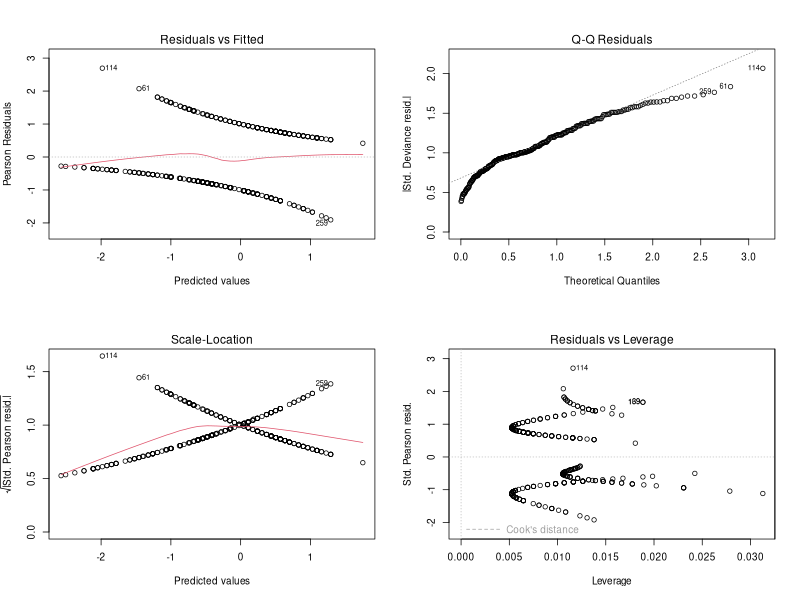

In [4]:
par(mfrow=c(2,2))
plot(mod)
par(mfrow=c(1,1))

### Plotting the Model Fit

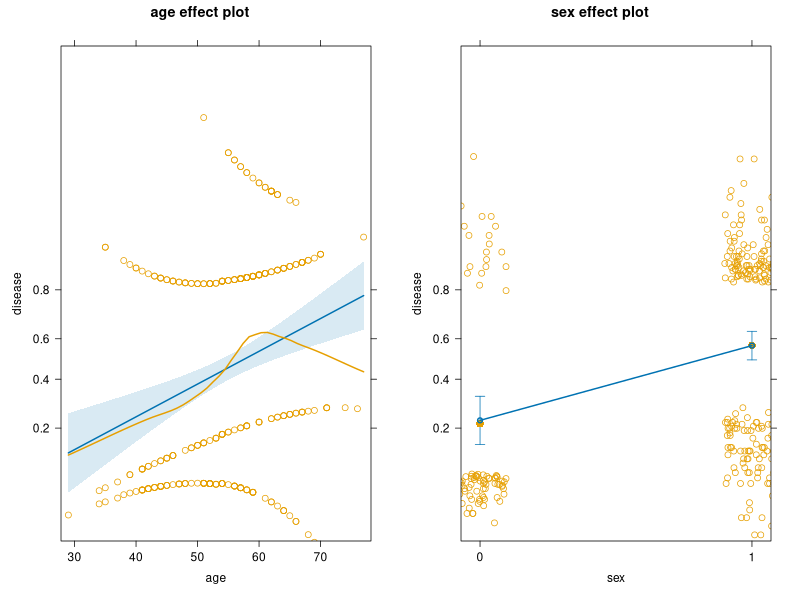

In [12]:
library('effects')
plot(allEffects(mod, partial.residuals=TRUE))

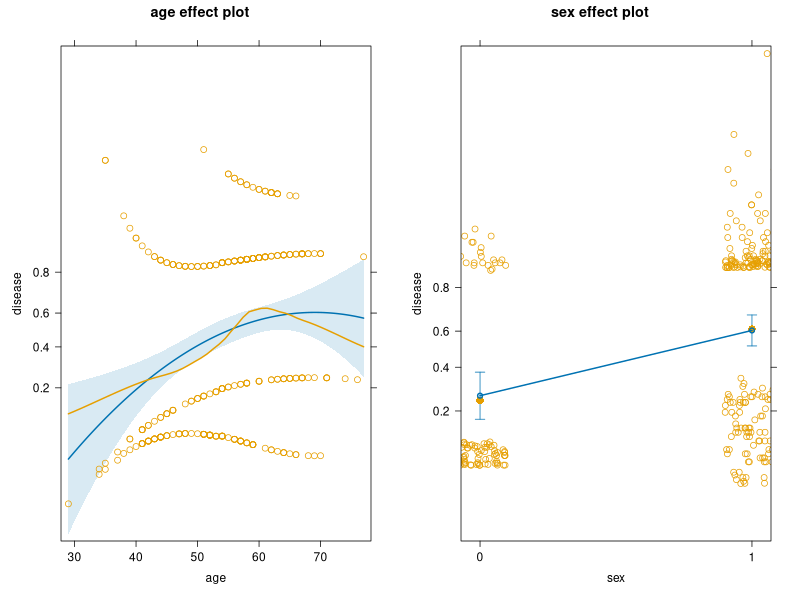

In [ ]:
mod.2 <- glm(disease ~ poly(age,2) + sex, family=binomial(link=logit), data=cleveland)
plot(allEffects(mod.2, partial.residuals=TRUE))

#### Options for Scaling Effects Displays

Notice that the `effects` package is smart enough to recognise that this is a logistic regression model and thus has transformed the prediction on to an easier scale. However, there are 3 possibilities here in terms of how this is displayed. These are compared visually and then explained below.


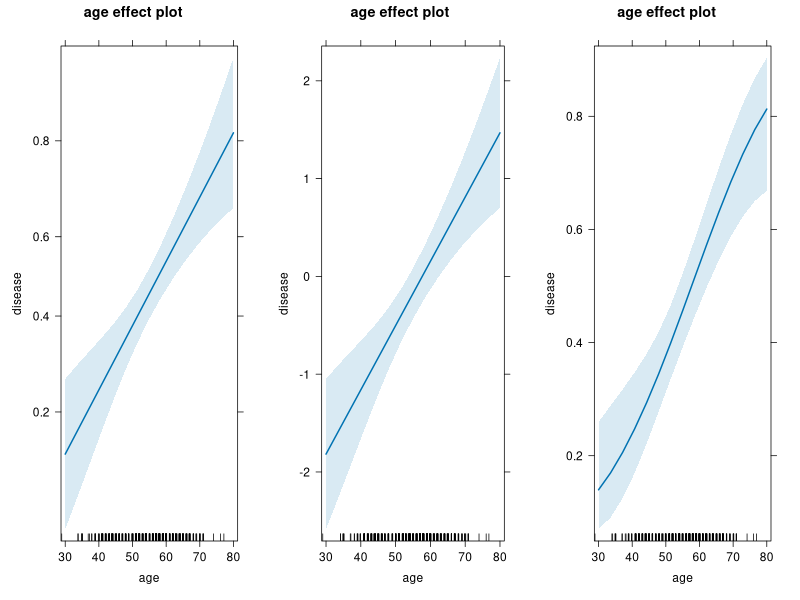

In [14]:
library(gridExtra)

# extract age effect
age.eff <- effect('age',mod)

# compare plots
p1 <- plot(age.eff, axes=list(y=list(type="rescale" ))) # link scale w/prob labels
p2 <- plot(age.eff, axes=list(y=list(type="link"    ))) # link scale
p3 <- plot(age.eff, axes=list(y=list(type="response"))) # probability scale

grid.arrange(p1, p2, p3, ncol=3)

The first plot (*left*) is the default and uses the option `type="rescale"`. This will draw the $y$-axis using the log-odds scale so that the fit is linear. However, to make this easier to interpret, probability labels will be written instead. For instance, a probability of 0.2 is equivalent to a log-odds of −1.386. So the plot places the label "0.2" at the location "-1.386" on the $y$-axis. Notice that the gap between 0.4 and 0.6 is not the same as the gap between 0.6 and 0.8. So the model fit is not linear on the probability scale.

The second plot (*middle*) uses the option `type="link"`, and will do exactly the same as above, but *without* the probability labels. As such, this is a direct plot of the model fit on the scale of the link function, meaning the $y$-axis is given in units of the log-odds.

The final plot (*right*) uses the option `type="response"`, and will draw the model fit on the true probability scale after piping the model through the inverse link function. This means that the S-shaped curved typified by the logit link will be visible on the plot.

In general, `"rescale"` or `"response"` are the most practical, as these present the effects on an interpretable scale in terms of probability. The log-odds scale is not very intuitive and would generally be a poor choice for visualisation. As such, the difference is largely between whether you want to see the sigmoidal curves, or would rather interpret the effects in terms of the straight-line fit.

## Inference on the Effects